# 16 — Harmoniser et fusionner des couches vectorielles

**Projet autonome · 30 minutes · données entièrement simulées**

Deux équipes ont relevé des villages avec des noms de champs et des types différents. Nous allons définir un schéma commun, conserver les identifiants textuels et distinguer un effectif nul d'un effectif inconnu. Chaque ligne de sortie gardera sa source et sa position d'origine.

La fusion réunit les enregistrements dans une couche. Elle ne regroupe pas les géométries, ne supprime pas les doublons et ne décide pas si deux relevés décrivent le même village. Ces décisions appartiennent à l'étude.

**À la fin du cours :** inspecter les schémas ; établir les correspondances ; choisir types, valeurs manquantes et conversions ; vérifier le fichier enregistré ; réutiliser la fusion dans une chaîne.

In [1]:
from pathlib import Path
import json
import sqlite3
import sys
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from IPython.display import display
%matplotlib inline

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from course import run_directory
import cartomize as cm

out = run_directory("16_harmonisation_fusion_vectorielle")
inputs = out / "entrees"
inputs.mkdir()
CRS = "EPSG:32733"
print("Cartomize", cm.__version__, "— nouveau dossier pédagogique :", out.name)

Cartomize 1.7.0 — nouveau dossier pédagogique : 16_harmonisation_fusion_vectorielle_h1c7f518


## 1. Deux relevés, deux schémas

Le relevé A stocke les habitants comme entiers avec valeurs manquantes. Le relevé B utilise du texte et possède un commentaire facultatif. Les codes `001` à `006` sont des identifiants : les convertir en nombres ferait perdre leurs zéros initiaux.

Le zéro du village `002` est une valeur renseignée. L'absence d'effectif pour `003` et `005` reste une information manquante. Les points et les effectifs sont inventés pour cet exercice ; leur SCR est commun et aucune reprojection n'est nécessaire.

In [2]:
a = gpd.GeoDataFrame({
    "code": ["001", "002", "003"],
    "nom": ["Mavoula", "Kimbala", "Ntombo"],
    "habitants": pd.array([120, 0, None], dtype="Int64"),
}, geometry=[Point(300000, 9500000), Point(300700, 9500300), Point(301200, 9499700)], crs=CRS)
b = gpd.GeoDataFrame({
    "village_id": ["004", "005", "006"],
    "village_name": ["Loubomo", "Bikouka", "N’Koulou"],
    "population": ["85", None, "210"],
    "commentaire": ["Observé", "", None],
}, geometry=[Point(301600, 9500500), Point(302300, 9500000), Point(302800, 9500800)], crs=CRS)

paths = [inputs / "releve_A.gpkg", inputs / "releve_B.gpkg"]
a.to_file(paths[0], layer="villages_A", driver="GPKG", index=False)
b.to_file(paths[1], layer="villages_B", driver="GPKG", index=False)
display(a.drop(columns="geometry"), b.drop(columns="geometry"))
assert len(a) + len(b) == 6

,code,nom,habitants
0,001,Mavoula,120
1,002,Kimbala,0
2,003,Ntombo,<NA>


,village_id,village_name,population,commentaire
0,004,Loubomo,85,Observé
1,005,Bikouka,NaN,
2,006,N’Koulou,210,NaN


## 2. Inspecter avant de choisir

`inspect_merge` présente les couches, leurs champs, les types et les valeurs manquantes. La correspondance indique **champ source → champ cible** et utilise l'identifiant de chaque source. Un champ non mentionné conserve son nom. La cible `None` signifierait une suppression volontaire.

Après correspondance, `habitants` reçoit des entiers d'un côté et du texte de l'autre. Nous choisissons donc explicitement son type dans le schéma final.

In [3]:
inspection = cm.inspect_merge(paths)
by_path = {Path(layer["path"]).name: layer for layer in inspection["layers"]}
field_maps = {
    by_path[paths[0].name]["id"]: {},
    by_path[paths[1].name]["id"]: {
        "village_id": "code", "village_name": "nom",
        "population": "habitants", "commentaire": "note",
    },
}
inspection = cm.inspect_merge(paths, field_maps=field_maps)
for layer in inspection["layers"]:
    print(layer["name"], "—", layer["features"], "entités")
    display(pd.DataFrame(layer["fields"])[["name", "type", "null_count", "target"]])
print("Conflits à résoudre par le schéma :", inspection["conflicts"])
assert inspection["conflicts"]

villages_A — 3 entités


,name,type,null_count,target
0,code,string,0,code
1,nom,string,0,nom
2,habitants,int64,1,habitants


villages_B — 3 entités


,name,type,null_count,target
0,village_id,string,0,code
1,village_name,string,0,nom
2,population,string,1,habitants
3,commentaire,string,1,note


Conflits à résoudre par le schéma : [{'field': 'habitants', 'types': ['int64', 'string'], 'reason': 'Choose an explicit target type and conversion policy.'}]


## 3. Fixer les conversions et les valeurs manquantes

Le schéma fixe les quatre champs métier et leur ordre. `code` et `nom` sont obligatoires ; `habitants` est un entier pouvant rester absent. Pour `note`, la valeur par défaut comble les valeurs nulles, y compris lorsque le champ n'existe pas dans une source. Une chaîne vide reste une chaîne vide.

Les conversions invalides sont refusées par défaut. Le moteur publie le nouveau dossier seulement après écriture et relecture des produits.

In [4]:
schema = {
    "code": {"type": "string", "nullable": False},
    "nom": {"type": "string", "nullable": False},
    "habitants": {"type": "int64", "nullable": True},
    "note": {"type": "string", "nullable": False, "default": "Non renseigné"},
}
result = cm.merge_layers(paths, out / "villages_fusionnes", schema=schema, field_maps=field_maps)
manifest = json.loads(result.manifest.read_text(encoding="utf-8"))
merged = cm.vector.read_file(result.data)
assert manifest["schema"] == "cartomize.vector_merge.v1"
assert manifest["source_count"] == 2 and manifest["feature_count"] == 6
assert all(path.is_file() for path in (result.data, result.manifest, result.report, result.issues))
print("Produits :", result.data.name, result.report.name, result.issues.name, result.manifest.name)
display(merged.drop(columns=merged.geometry.name))

Produits : merged.gpkg fields.csv issues.csv manifest.json


,code,nom,habitants,note,cm_source_id,cm_source_name,cm_source_path,cm_source_layer,cm_source_row
0,001,Mavoula,120,Non renseigné,villages_A_48f46b2480b1,villages_A,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_A,0
1,002,Kimbala,0,Non renseigné,villages_A_48f46b2480b1,villages_A,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_A,1
2,003,Ntombo,<NA>,Non renseigné,villages_A_48f46b2480b1,villages_A,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_A,2
3,004,Loubomo,85,Observé,villages_B_67eda5e6e404,villages_B,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_B,0
4,005,Bikouka,<NA>,,villages_B_67eda5e6e404,villages_B,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_B,1
5,006,N’Koulou,210,Non renseigné,villages_B_67eda5e6e404,villages_B,/workspace/scratch/e5f7833bf66a/cartomize-pyth...,villages_B,2


## 4. Contrôler le fichier avec une référence indépendante

La liste attendue ci-dessous est écrite à partir des six relevés. Elle ne réutilise pas une seconde concaténation comme référence. SQLite relit les valeurs enregistrées et distingue les entiers de `NULL`. La provenance permet de revenir à la source et à sa ligne, numérotée à partir de zéro.

In [5]:
expected = [
    ("001", "Mavoula", 120, "Non renseigné"),
    ("002", "Kimbala", 0, "Non renseigné"),
    ("003", "Ntombo", None, "Non renseigné"),
    ("004", "Loubomo", 85, "Observé"),
    ("005", "Bikouka", None, ""),
    ("006", "N’Koulou", 210, "Non renseigné"),
]
with sqlite3.connect(result.data) as connection:
    actual = connection.execute('SELECT code, nom, habitants, note FROM features ORDER BY rowid').fetchall()
assert actual == expected
assert all(row[2] is None or type(row[2]) is int for row in actual)
assert sum(row[2] for row in actual if row[2] is not None) == 415
assert sum(row[2] is None for row in actual) == 2
assert sum(row[2] == 0 for row in actual) == 1
assert merged.geometry.to_wkb().tolist() == a.geometry.to_wkb().tolist() + b.geometry.to_wkb().tolist()

provenance = manifest["provenance_columns"]
assert len(set(provenance.values())) == 5
assert merged[provenance["source_row"]].tolist() == [0, 1, 2, 0, 1, 2]
assert merged[provenance["source_id"]].tolist() == [by_path[paths[0].name]["id"]] * 3 + [by_path[paths[1].name]["id"]] * 3
print("6 lignes, 415 habitants renseignés, 2 effectifs inconnus et 1 zéro conservés.")
display(merged[["code", provenance["source_name"], provenance["source_row"]]])

6 lignes, 415 habitants renseignés, 2 effectifs inconnus et 1 zéro conservés.


,code,cm_source_name,cm_source_row
0,001,villages_A,0
1,002,villages_A,1
2,003,villages_A,2
3,004,villages_B,0
4,005,villages_B,1
5,006,villages_B,2


## 5. Une conversion invalide exige une décision

Nous introduisons une erreur volontaire dans une copie en mémoire : `85 habitants` n'est pas un entier. Le mode strict refuse la fusion sans publier de dossier. `conversion_errors="null"` autorise explicitement le remplacement de cette valeur par une absence, et l'anomalie est conservée dans le CSV des problèmes. Cette décision ne corrige pas la donnée de terrain.

In [6]:
invalid = b.copy()
invalid.loc[0, "population"] = "85 habitants"
invalid_sources = [{"data": a, "name": "releve_A"}, {"data": invalid, "name": "releve_B_invalide"}]
invalid_layers = cm.inspect_merge(invalid_sources)["layers"]
invalid_maps = {
    invalid_layers[0]["id"]: {},
    invalid_layers[1]["id"]: field_maps[by_path[paths[1].name]["id"]],
}
refused = out / "conversion_refusee"
try:
    cm.merge_layers(invalid_sources, refused, schema=schema, field_maps=invalid_maps)
except ValueError as exc:
    print("Refus attendu :", exc)
else:
    raise AssertionError("La valeur invalide devait être refusée.")
assert not refused.exists()
accepted = cm.merge_layers(invalid_sources, out / "conversion_explicitement_nulle",
                           schema=schema, field_maps=invalid_maps, conversion_errors="null")
accepted_data = cm.vector.read_file(accepted.data)
assert accepted_data["habitants"].isna().sum() == 3
assert "85 habitants" in accepted.issues.read_text(encoding="utf-8")
assert b.loc[0, "population"] == "85"
display(pd.read_csv(accepted.issues))

Refus attendu : releve_B_invalide, row 0, field 'population' -> 'habitants': Expected a decimal integer.


,source_id,source_row,source_field,target_field,value,reason,action
0,releve_B_invalide_2156d1a28ad1,0,population,habitants,"""85 habitants""",Expected a decimal integer.,NaN


## 6. Réutiliser la couche dans un plan

L'opérateur commun est `vector.merge_layers`. Ses produits nommés comprennent `data`, `manifest`, `report` et `issues`. Ici, `@fusion:data` alimente des tampons de 100 m. Le SCR projeté a été choisi en amont ; la fusion ne le modifie pas.

In [7]:
plan = cm.processing_plan([
    {"id": "fusion", "operation": "vector.merge_layers",
     "parameters": {"sources": [str(path) for path in paths], "schema": schema, "field_maps": field_maps}},
    {"id": "tampons", "operation": "vector.buffer",
     "parameters": {"data": "@fusion:data", "distance": 100}},
])
journal = cm.run_plan(plan, out / "chaine_fusion")
record = json.loads(journal.read_text(encoding="utf-8"))
buffers = cm.vector.read_file(record["products"]["tampons"]["primary"])
assert len(buffers) == 6 and set(buffers.geom_type) == {"Polygon"}
print("Le plan a produit les six tampons à partir de la couche harmonisée.")

Le plan a produit les six tampons à partir de la couche harmonisée.


## 7. Lire ensemble la géographie et les attributs

La carte conserve les six points. Le graphique distingue visuellement les effectifs inconnus et le zéro renseigné. Les valeurs ne permettent aucune conclusion sur un territoire réel : ce sont les données simulées de l'exercice.

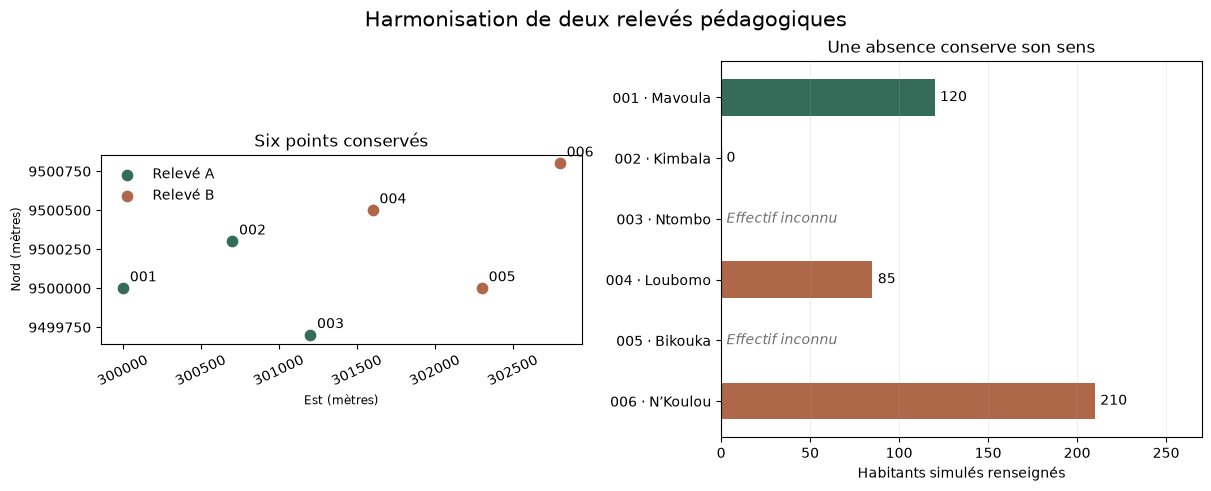

,produit
0,chaine_fusion/automation.json
1,chaine_fusion/fusion/operation.json
2,chaine_fusion/fusion/products/fields.csv
3,chaine_fusion/fusion/products/issues.csv
4,chaine_fusion/fusion/products/manifest.json
5,chaine_fusion/fusion/products/merged.gpkg
6,chaine_fusion/tampons/operation.json
7,chaine_fusion/tampons/result.gpkg
8,conversion_explicitement_nulle/fields.csv
9,conversion_explicitement_nulle/issues.csv


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
a.plot(ax=axes[0], color="#356c59", markersize=55, label="Relevé A")
b.plot(ax=axes[0], color="#ae6749", markersize=55, label="Relevé B")
for _, row in merged.iterrows():
    axes[0].annotate(row["code"], (row.geometry.x, row.geometry.y), xytext=(5, 5), textcoords="offset points")
axes[0].set_title("Six points conservés")
axes[0].set_xlabel("Est (mètres)")
axes[0].set_ylabel("Nord (mètres)")
axes[0].legend(frameon=False)
axes[0].ticklabel_format(style="plain", useOffset=False)
axes[0].tick_params(axis="x", rotation=25)
for position, row in enumerate(expected):
    if row[2] is None:
        axes[1].text(3, position, "Effectif inconnu", va="center", color="#6f6f6f", fontstyle="italic")
    elif row[2] == 0:
        axes[1].plot([0], [position], marker="|", markersize=14, color="#356c59")
        axes[1].text(3, position, "0", va="center")
    else:
        axes[1].barh(position, row[2], color="#356c59" if position < 3 else "#ae6749", height=.6)
        axes[1].text(row[2] + 3, position, str(row[2]), va="center")
axes[1].set_yticks(range(6), [row[0] + " · " + row[1] for row in expected])
axes[1].set_ylim(5.6, -.6)
axes[1].set_xlim(0, 270)
axes[1].set_xlabel("Habitants simulés renseignés")
axes[1].set_title("Une absence conserve son sens")
axes[1].grid(axis="x", alpha=.2)
fig.suptitle("Harmonisation de deux relevés pédagogiques", fontsize=15)
fig.savefig(out / "fusion_et_valeurs_manquantes.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()
display(pd.DataFrame({"produit": [p.relative_to(out).as_posix() for p in sorted(out.rglob("*")) if p.is_file()]}))

## Passer aux données de l'étude

Examiner les unités, les nomenclatures et le sens des champs avant d'établir les correspondances. Le schéma peut aussi utiliser `float64`, `boolean`, `date`, `datetime` ou `datetime_utc`. Les dates et heures ont des règles explicites ; une heure naïve n'est pas interprétée implicitement comme UTC.

`missing_fields="error"` refuse un champ cible absent d'une source. `extra_fields="error"`, valeur par défaut avec un schéma explicite, évite de supprimer silencieusement des champs. Une valeur `None` dans la correspondance ou `extra_fields="drop"` rend cette suppression explicite. Une colonne non nullable refuse les absences restantes après application de sa valeur par défaut.

Sans SCR cible, les sources doivent déjà avoir le même SCR. Une reprojection demandée explicitement réutilise le [module M09](../../docs/VECTOR_REPROJECTION.md) et ses règles géodésiques. La fusion ne réalise ni union géométrique, ni dissolution, ni déduplication.

**Exercice.** Peut-on remplacer les deux effectifs inconnus par zéro pour obtenir une table entièrement numérique ?

**Réponse.** Seulement si cette interprétation est justifiée par l'étude. Le zéro exprime un effectif renseigné nul ; une absence exprime l'absence d'information. Le type entier nullable permet de conserver les deux sans inventer une valeur.

Voir le [guide M10](../../docs/VECTOR_MERGE.md), la [validation réelle](../../docs/VALIDATION_M10_REAL.json) et la [documentation Esri Merge, référence R016](https://doc.esri.com/en/arcgis-pro/latest/tool-reference/data-management/merge.html).